In [1]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Load the Sephora product dataset
df = pd.read_csv("../data/raw/product_info.csv")

# Display the first five rows
df.head()


Matplotlib is building the font cache; this may take a moment.


,product_id,product_name,brand_id,brand_name,loves_count,rating,reviews,size,variation_type,variation_value,...,online_only,out_of_stock,sephora_exclusive,highlights,primary_category,secondary_category,tertiary_category,child_count,child_max_price,child_min_price
0,P473671,Fragrance Discovery Set,6342,19-69,6320,3.6364,11.0,NaN,NaN,NaN,...,1,0,0,"['Unisex/ Genderless Scent', 'Warm &Spicy Scen...",Fragrance,Value & Gift Sets,Perfume Gift Sets,0,NaN,NaN
1,P473668,La Habana Eau de Parfum,6342,19-69,3827,4.1538,13.0,3.4 oz/ 100 mL,Size + Concentration + Formulation,3.4 oz/ 100 mL,...,1,0,0,"['Unisex/ Genderless Scent', 'Layerable Scent'...",Fragrance,Women,Perfume,2,85.0,30.0
2,P473662,Rainbow Bar Eau de Parfum,6342,19-69,3253,4.2500,16.0,3.4 oz/ 100 mL,Size + Concentration + Formulation,3.4 oz/ 100 mL,...,1,0,0,"['Unisex/ Genderless Scent', 'Layerable Scent'...",Fragrance,Women,Perfume,2,75.0,30.0
3,P473660,Kasbah Eau de Parfum,6342,19-69,3018,4.4762,21.0,3.4 oz/ 100 mL,Size + Concentration + Formulation,3.4 oz/ 100 mL,...,1,0,0,"['Unisex/ Genderless Scent', 'Layerable Scent'...",Fragrance,Women,Perfume,2,75.0,30.0
4,P473658,Purple Haze Eau de Parfum,6342,19-69,2691,3.2308,13.0,3.4 oz/ 100 mL,Size + Concentration + Formulation,3.4 oz/ 100 mL,...,1,0,0,"['Unisex/ Genderless Scent', 'Layerable Scent'...",Fragrance,Women,Perfume,2,75.0,30.0


In [2]:
# Dataset overview
print("DATASET OVERVIEW")
print("-" * 40)

print("Number of rows:", df.shape[0])
print("Number of columns:", df.shape[1])

print("\nColumn names:")
print(df.columns.tolist())

print("\nData types and non-null values:")
df.info()

DATASET OVERVIEW
----------------------------------------
Number of rows: 8494
Number of columns: 27

Column names:
['product_id', 'product_name', 'brand_id', 'brand_name', 'loves_count', 'rating', 'reviews', 'size', 'variation_type', 'variation_value', 'variation_desc', 'ingredients', 'price_usd', 'value_price_usd', 'sale_price_usd', 'limited_edition', 'new', 'online_only', 'out_of_stock', 'sephora_exclusive', 'highlights', 'primary_category', 'secondary_category', 'tertiary_category', 'child_count', 'child_max_price', 'child_min_price']

Data types and non-null values:
<class 'pandas.DataFrame'>
RangeIndex: 8494 entries, 0 to 8493
Data columns (total 27 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   product_id          8494 non-null   str    
 1   product_name        8494 non-null   str    
 2   brand_id            8494 non-null   int64  
 3   brand_name          8494 non-null   str    
 4   loves_count         8494 no

In [3]:

# Missing Value Analysis

missing_count = df.isnull().sum()

missing_percentage = (missing_count / len(df)) * 100

missing_df = pd.DataFrame({
    "Missing Count": missing_count,
    "Missing Percentage (%)": missing_percentage
})

# Sort columns by missing values
missing_df = missing_df.sort_values(
    by="Missing Count",
    ascending=False
)

# Display only columns with missing values
missing_df[missing_df["Missing Count"] > 0]


,Missing Count,Missing Percentage (%)
sale_price_usd,8224,96.821286
value_price_usd,8043,94.690370
variation_desc,7244,85.283730
child_max_price,5740,67.577113
child_min_price,5740,67.577113
highlights,2207,25.983047
size,1631,19.201789
variation_value,1598,18.813280
variation_type,1444,17.000235
tertiary_category,990,11.655286


In [4]:

# Duplicate Analysis

print("DUPLICATE ANALYSIS")
print("-" * 40)

# Count completely duplicated rows
duplicate_rows = df.duplicated().sum()

print("Number of duplicate rows:", duplicate_rows)

# Count duplicated product IDs
duplicate_products = df.duplicated(subset=["product_id"]).sum()

print("Number of duplicate product IDs:", duplicate_products)

# Display duplicated products if they exist
if duplicate_products > 0:
    display(
        df[df.duplicated(subset=["product_id"], keep=False)]
        .sort_values("product_id")
    )
else:
    print("No duplicate product IDs found.")


DUPLICATE ANALYSIS
----------------------------------------
Number of duplicate rows: 0
Number of duplicate product IDs: 0
No duplicate product IDs found.


PRODUCT CATEGORY DISTRIBUTION
----------------------------------------
primary_category
Skincare           2420
Makeup             2369
Hair               1464
Fragrance          1432
Bath & Body         405
Mini Size           288
Men                  60
Tools & Brushes      52
Gifts                 4
Name: count, dtype: int64


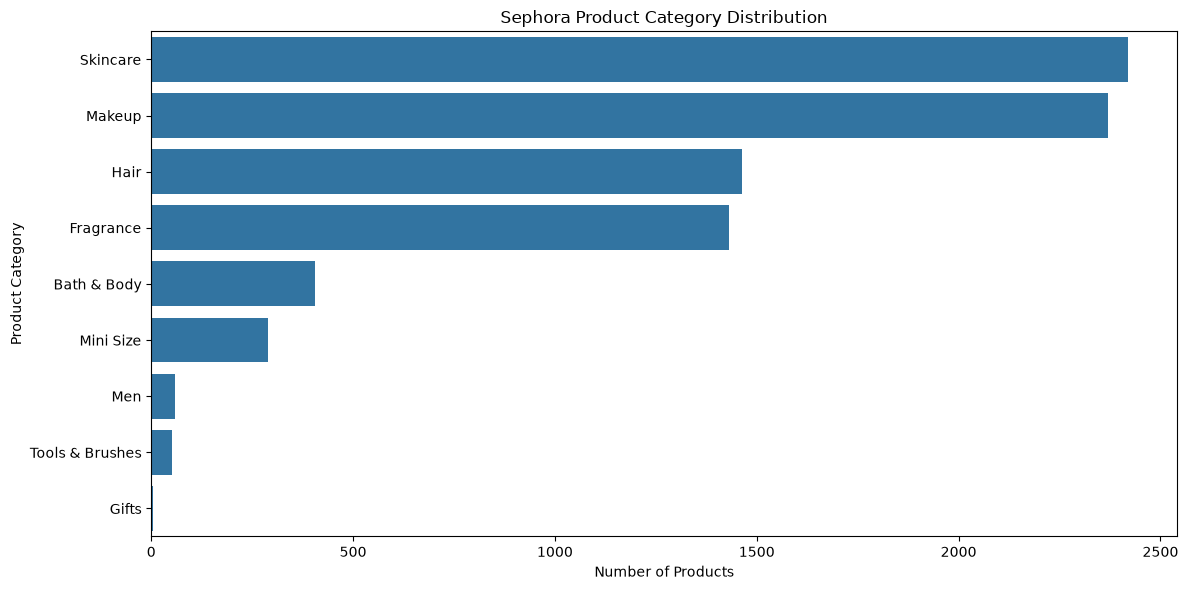

In [5]:

# Category Distribution Analysis

category_counts = df["primary_category"].value_counts()

print("PRODUCT CATEGORY DISTRIBUTION")
print("-" * 40)
print(category_counts)

# Visualize category distribution
plt.figure(figsize=(12, 6))

sns.barplot(
    x=category_counts.values,
    y=category_counts.index
)

plt.title("Sephora Product Category Distribution")
plt.xlabel("Number of Products")
plt.ylabel("Product Category")

plt.tight_layout()
plt.show()


RATING ANALYSIS
----------------------------------------
count    8216.000000
mean        4.194513
std         0.516694
min         1.000000
25%         3.981725
50%         4.289350
75%         4.530525
max         5.000000
Name: rating, dtype: float64

Products without ratings:
278


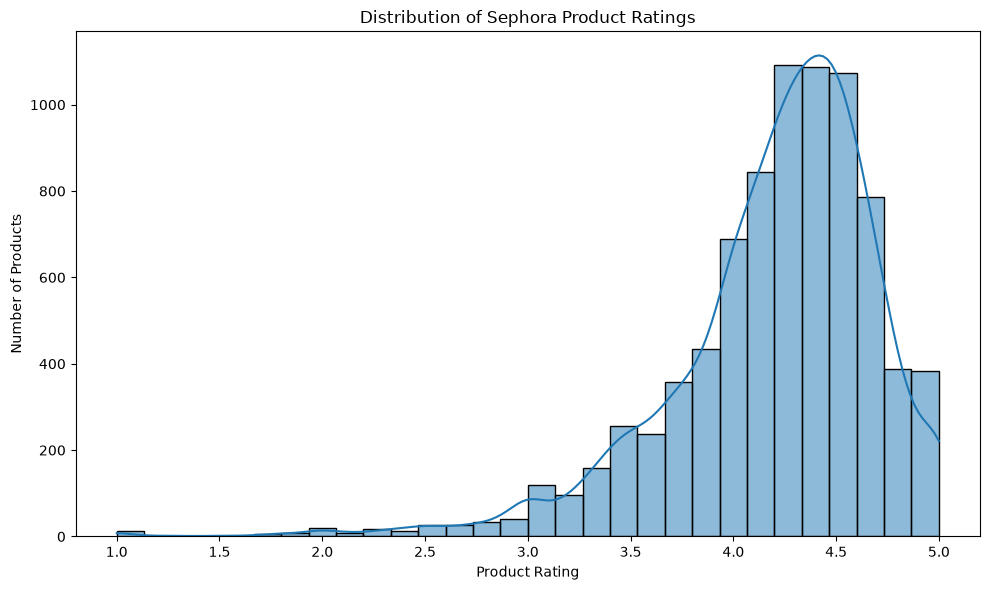

In [6]:

# Rating Distribution Analysis

print("RATING ANALYSIS")
print("-" * 40)

print(df["rating"].describe())

print("\nProducts without ratings:")
print(df["rating"].isnull().sum())

plt.figure(figsize=(10, 6))

sns.histplot(
    data=df,
    x="rating",
    bins=30,
    kde=True
)

plt.title("Distribution of Sephora Product Ratings")
plt.xlabel("Product Rating")
plt.ylabel("Number of Products")

plt.tight_layout()
plt.show()


TOP 15 BRANDS
----------------------------------------
brand_name
SEPHORA COLLECTION         352
CLINIQUE                   179
Dior                       136
tarte                      131
NEST New York              115
Bumble and bumble          110
Kérastase                  108
TOM FORD                   100
Charlotte Tilbury           99
Anastasia Beverly Hills     95
Oribe                       94
Moroccanoil                 91
Jo Malone London            88
Hourglass                   87
Fenty Beauty by Rihanna     82
Name: count, dtype: int64


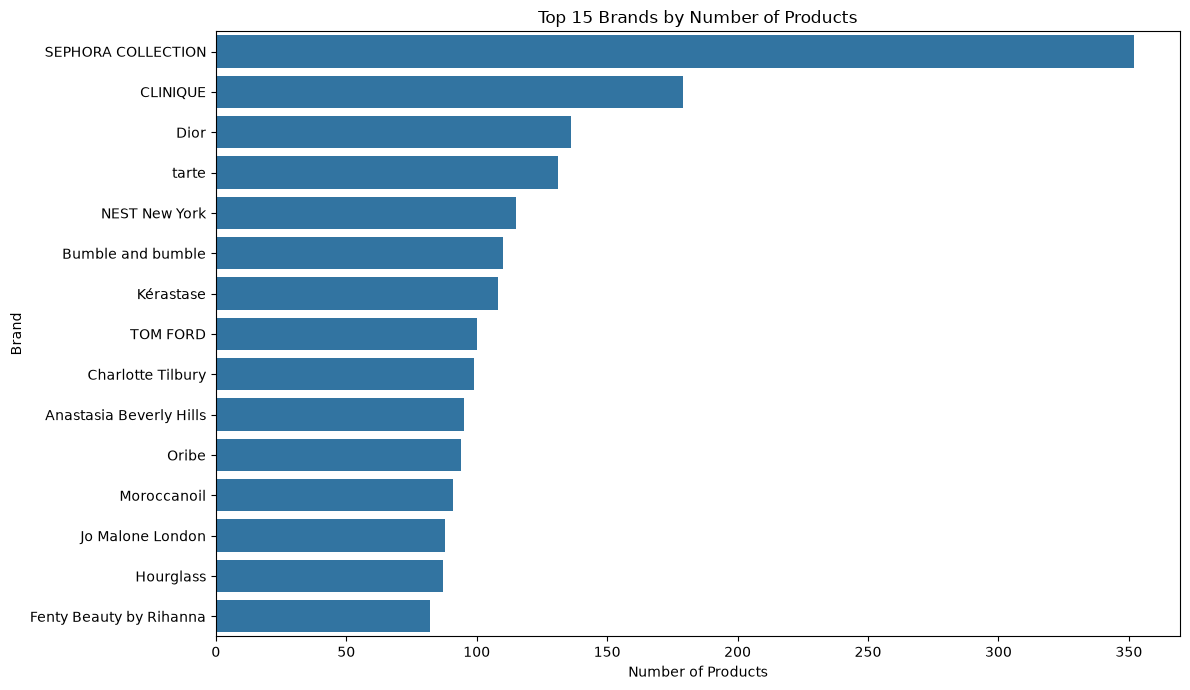

In [7]:

# Top 15 Brands Analysis

top_brands = df["brand_name"].value_counts().head(15)

print("TOP 15 BRANDS")
print("-" * 40)
print(top_brands)

plt.figure(figsize=(12, 7))

sns.barplot(
    x=top_brands.values,
    y=top_brands.index
)

plt.title("Top 15 Brands by Number of Products")
plt.xlabel("Number of Products")
plt.ylabel("Brand")

plt.tight_layout()
plt.show()


PRICE ANALYSIS
----------------------------------------
count    8494.000000
mean       51.655595
std        53.669234
min         3.000000
25%        25.000000
50%        35.000000
75%        58.000000
max      1900.000000
Name: price_usd, dtype: float64


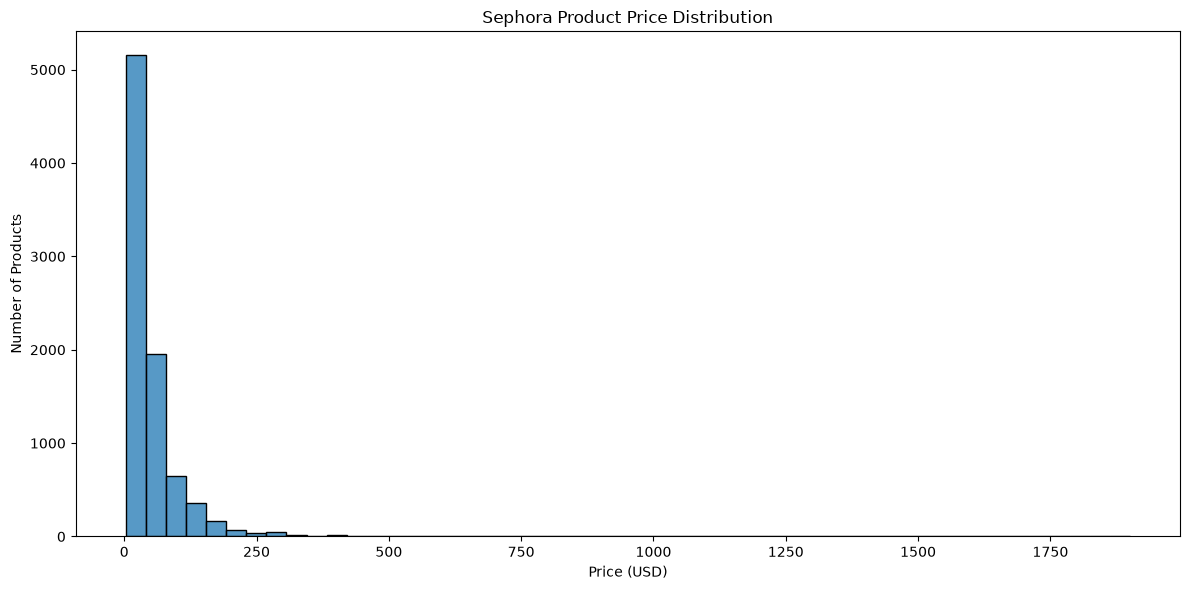

In [8]:

# Product Price Analysis

print("PRICE ANALYSIS")
print("-" * 40)

print(df["price_usd"].describe())

plt.figure(figsize=(12, 6))

sns.histplot(
    data=df,
    x="price_usd",
    bins=50
)

plt.title("Sephora Product Price Distribution")
plt.xlabel("Price (USD)")
plt.ylabel("Number of Products")

plt.tight_layout()
plt.show()


AVERAGE PRICE BY CATEGORY
----------------------------------------
primary_category
Fragrance          87.26
Skincare           60.51
Gifts              50.00
Hair               42.79
Bath & Body        42.23
Men                33.20
Makeup             32.76
Tools & Brushes    31.92
Mini Size          21.40
Name: price_usd, dtype: float64


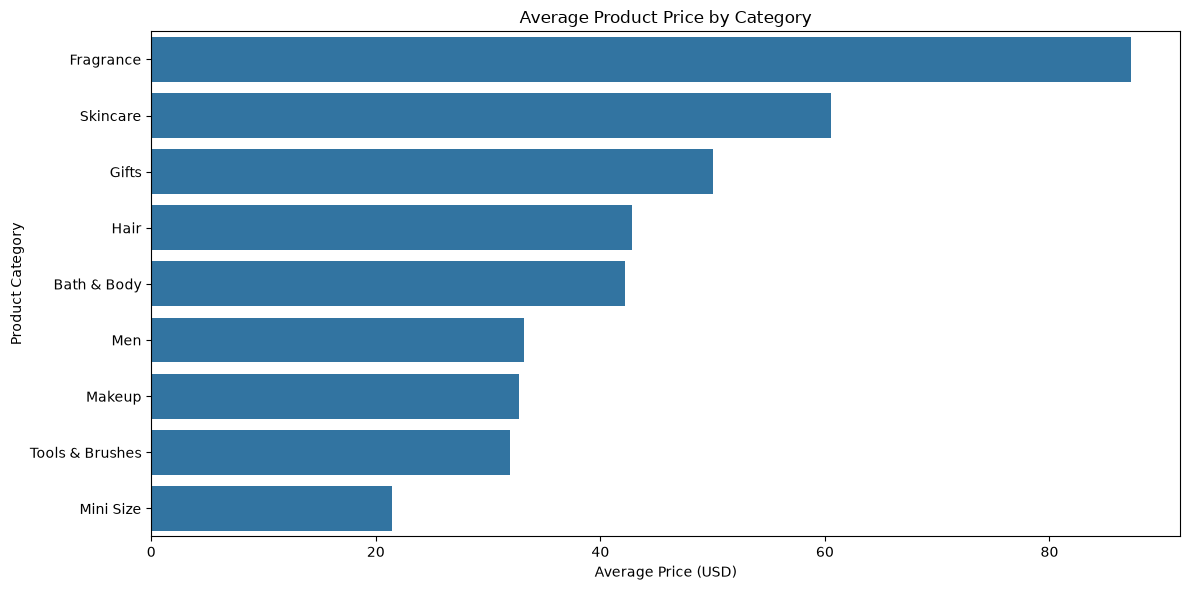

In [9]:

# Average Price by Product Category

avg_price_category = (
    df.groupby("primary_category")["price_usd"]
    .mean()
    .sort_values(ascending=False)
)

print("AVERAGE PRICE BY CATEGORY")
print("-" * 40)
print(avg_price_category.round(2))

plt.figure(figsize=(12, 6))

sns.barplot(
    x=avg_price_category.values,
    y=avg_price_category.index
)

plt.title("Average Product Price by Category")
plt.xlabel("Average Price (USD)")
plt.ylabel("Product Category")

plt.tight_layout()
plt.show()


TOP 10 MOST LOVED PRODUCTS


,product_name,brand_name,loves_count,rating
6242,Soft Pinch Liquid Blush,Rare Beauty by Selena Gomez,1401068,4.5356
5249,Radiant Creamy Concealer,NARS,1153594,4.3080
4431,Lip Sleeping Mask Intense Hydration with Vitam...,LANEIGE,1081315,4.3508
6434,Cream Lip Stain Liquid Lipstick,SEPHORA COLLECTION,1029051,4.3201
2523,Gloss Bomb Universal Lip Luminizer,Fenty Beauty by Rihanna,968317,4.6357
2524,Pro Filt’r Soft Matte Longwear Liquid Foundation,Fenty Beauty by Rihanna,856497,4.0356
5250,Blush,NARS,840076,4.6643
247,Brow Wiz Ultra-Slim Precision Brow Pencil,Anastasia Beverly Hills,834189,4.4056
4458,Translucent Loose Setting Powder,Laura Mercier,813497,4.5029
7648,Niacinamide 10% + Zinc 1% Oil Control Serum,The Ordinary,763168,4.2439


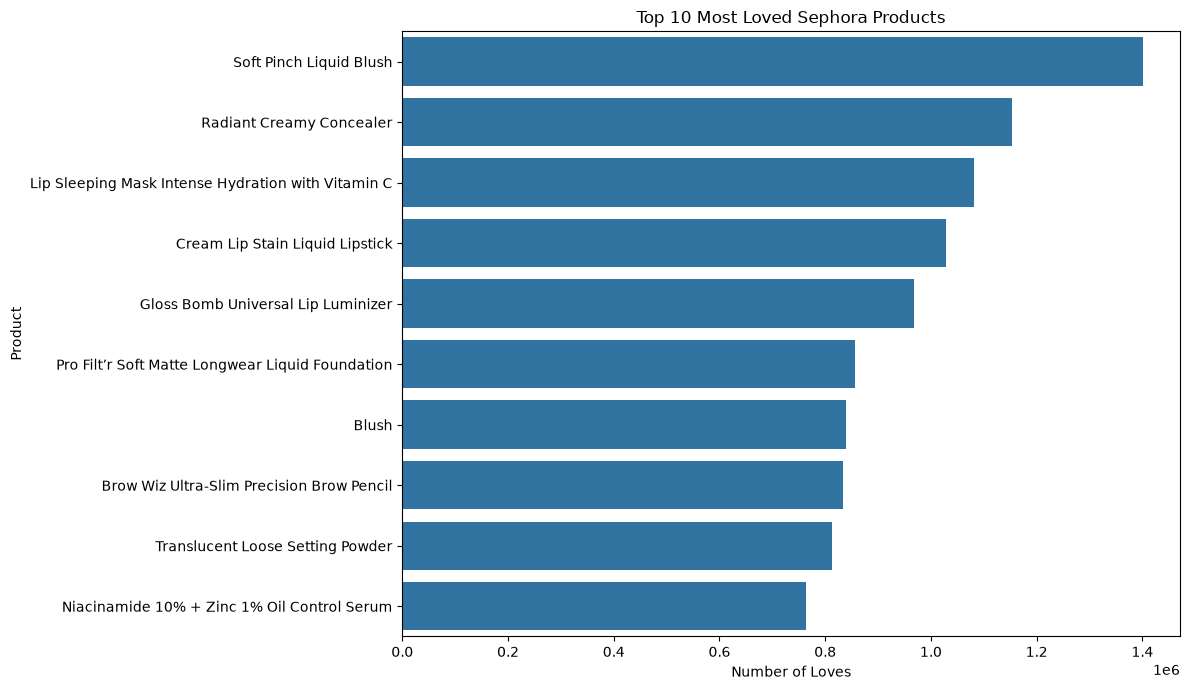

In [10]:

# Product Popularity Analysis

top_popular_products = df.nlargest(
    10,
    "loves_count"
)[
    ["product_name", "brand_name", "loves_count", "rating"]
]

print("TOP 10 MOST LOVED PRODUCTS")

display(top_popular_products)

plt.figure(figsize=(12, 7))

sns.barplot(
    data=top_popular_products,
    x="loves_count",
    y="product_name"
)

plt.title("Top 10 Most Loved Sephora Products")
plt.xlabel("Number of Loves")
plt.ylabel("Product")

plt.tight_layout()
plt.show()


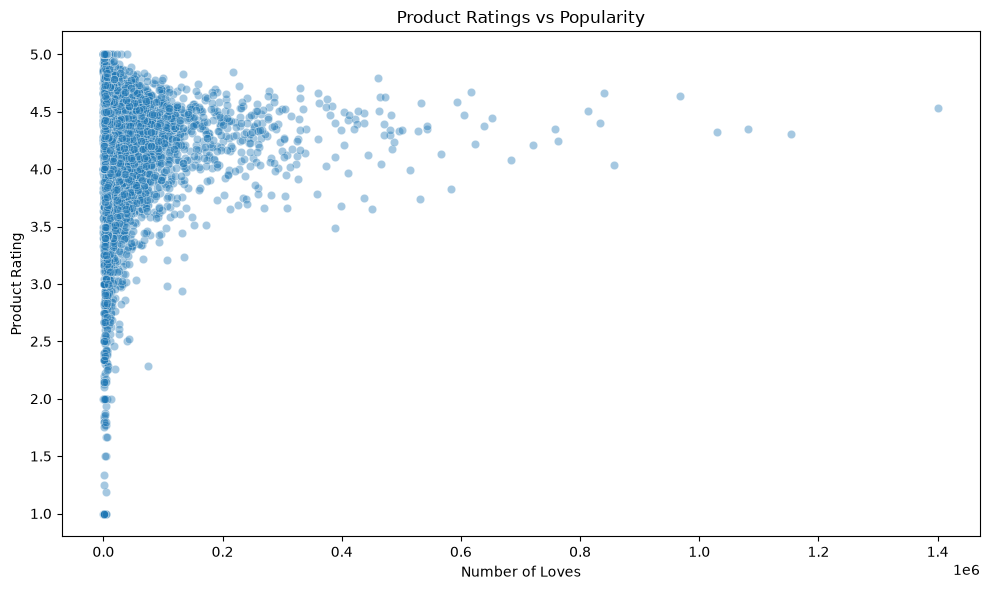

Correlation Matrix:


,rating,loves_count
rating,1.000000,0.041797
loves_count,0.041797,1.000000


In [11]:

# Rating vs Product Popularity

plt.figure(figsize=(10, 6))

sns.scatterplot(
    data=df,
    x="loves_count",
    y="rating",
    alpha=0.4
)

plt.title("Product Ratings vs Popularity")
plt.xlabel("Number of Loves")
plt.ylabel("Product Rating")

plt.tight_layout()
plt.show()

correlation = df[
    ["rating", "loves_count"]
].corr()

print("Correlation Matrix:")
display(correlation)


TOP 15 SECONDARY CATEGORIES
secondary_category
Women                        875
Hair Styling & Treatments    757
Eye                          711
Face                         659
Moisturizers                 551
Value & Gift Sets            498
Treatments                   466
Shampoo & Conditioner        431
Lip                          411
Cleansers                    361
Candles & Home Scents        263
Brushes & Applicators        246
Body Moisturizers            220
Mini Size                    187
Eye Care                     186
Name: count, dtype: int64


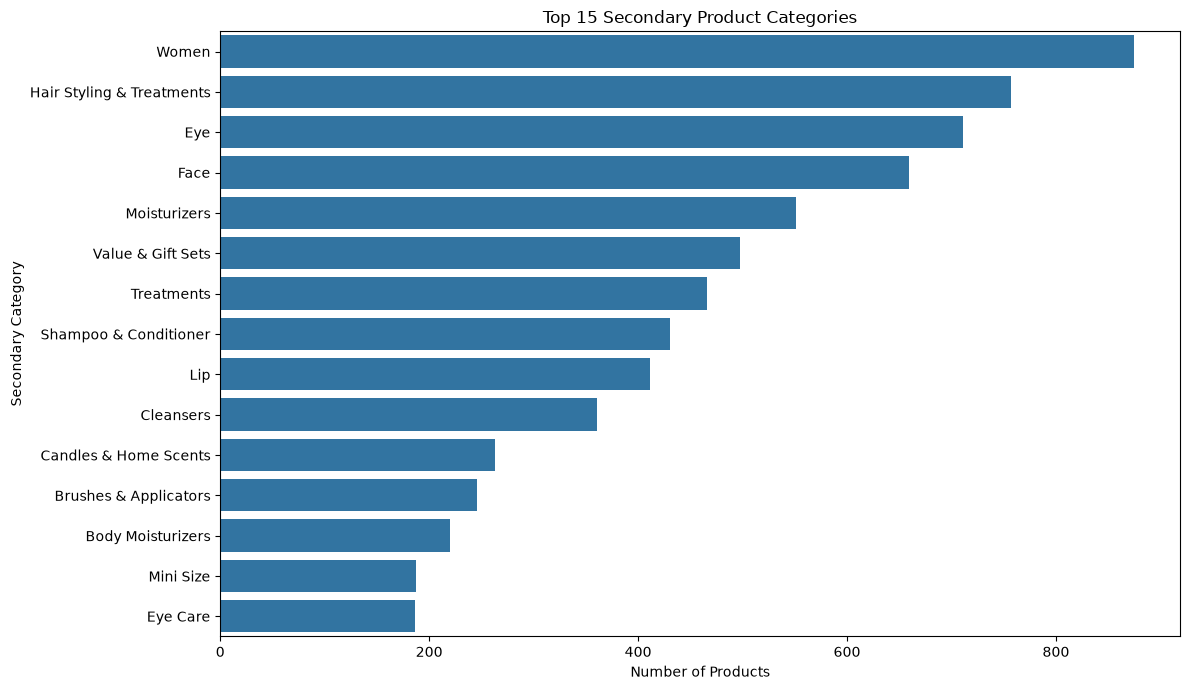

In [12]:

# Secondary Category Distribution

secondary_counts = (
    df["secondary_category"]
    .value_counts()
    .head(15)
)

print("TOP 15 SECONDARY CATEGORIES")
print(secondary_counts)

plt.figure(figsize=(12, 7))

sns.barplot(
    x=secondary_counts.values,
    y=secondary_counts.index
)

plt.title("Top 15 Secondary Product Categories")
plt.xlabel("Number of Products")
plt.ylabel("Secondary Category")

plt.tight_layout()
plt.show()


In [13]:

# Content Feature Analysis

content_columns = [
    "product_name",
    "brand_name",
    "ingredients",
    "highlights",
    "primary_category",
    "secondary_category",
    "tertiary_category"
]

content_summary = pd.DataFrame({
    "Non-Null Count": df[content_columns].notna().sum(),
    "Missing Count": df[content_columns].isna().sum(),
    "Missing Percentage (%)": (
        df[content_columns].isna().mean() * 100
    ).round(2),
    "Unique Values": df[content_columns].nunique()
})

print("CONTENT FEATURE SUMMARY")
display(content_summary)


CONTENT FEATURE SUMMARY


,Non-Null Count,Missing Count,Missing Percentage (%),Unique Values
product_name,8494,0,0.00,8415
brand_name,8494,0,0.00,304
ingredients,7549,945,11.13,6538
highlights,6287,2207,25.98,4417
primary_category,8494,0,0.00,9
secondary_category,8486,8,0.09,41
tertiary_category,7504,990,11.66,118


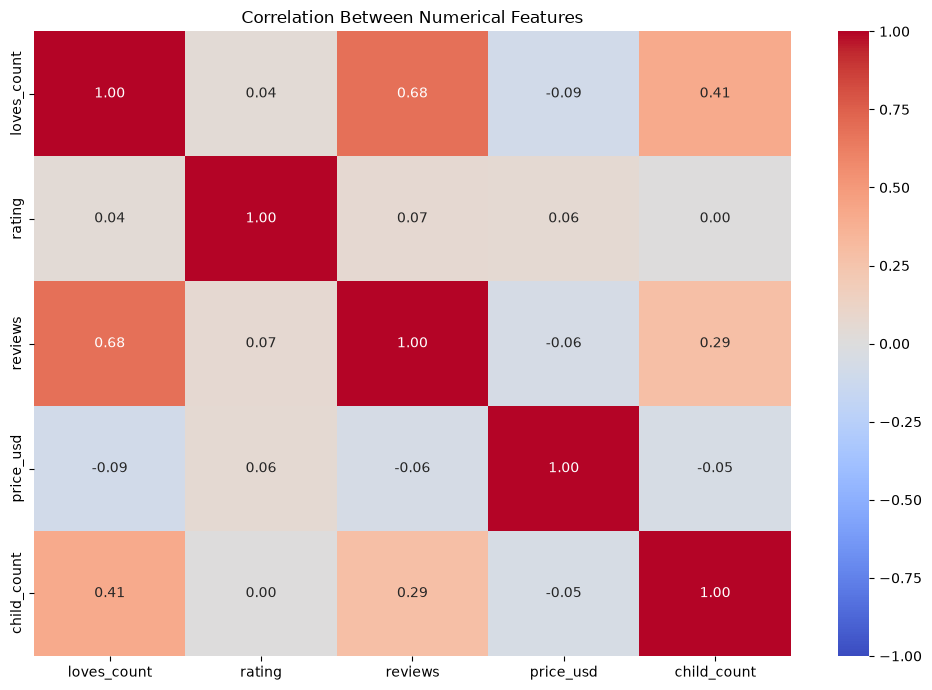

In [14]:

# Numerical Feature Correlation Analysis

numerical_columns = [
    "loves_count",
    "rating",
    "reviews",
    "price_usd",
    "child_count"
]

correlation_matrix = df[numerical_columns].corr()

plt.figure(figsize=(10, 7))

sns.heatmap(
    correlation_matrix,
    annot=True,
    cmap="coolwarm",
    fmt=".2f",
    vmin=-1,
    vmax=1
)

plt.title("Correlation Between Numerical Features")

plt.tight_layout()
plt.show()


In [15]:

# Data Cleaning

# Create a copy to preserve the original dataset
df_clean = df.copy()

# Remove duplicate records if any
df_clean = df_clean.drop_duplicates(
    subset=["product_id"]
).copy()

# Fill missing textual content
text_columns = [
    "product_name",
    "brand_name",
    "ingredients",
    "highlights",
    "primary_category",
    "secondary_category",
    "tertiary_category"
]

for col in text_columns:
    df_clean[col] = df_clean[col].fillna("")

# Remove unnecessary whitespace
for col in text_columns:
    df_clean[col] = (
        df_clean[col]
        .astype(str)
        .str.strip()
    )

# Remove products without a usable name
df_clean = df_clean[
    df_clean["product_name"] != ""
].copy()

print("Original dataset:", df.shape)
print("Cleaned dataset:", df_clean.shape)

print("\nRemaining missing content values:")
print(df_clean[text_columns].isnull().sum())


Original dataset: (8494, 27)
Cleaned dataset: (8494, 27)

Remaining missing content values:
product_name          0
brand_name            0
ingredients           0
highlights            0
primary_category      0
secondary_category    0
tertiary_category     0
dtype: int64


In [16]:

# Feature Engineering for Content-Based Filtering

# Create combined product content
df_clean["combined_features"] = (
    df_clean["product_name"] + " " +
    df_clean["brand_name"] + " " +
    df_clean["primary_category"] + " " +
    df_clean["secondary_category"] + " " +
    df_clean["tertiary_category"] + " " +
    df_clean["highlights"] + " " +
    df_clean["ingredients"]
)

# Normalize whitespace
df_clean["combined_features"] = (
    df_clean["combined_features"]
    .str.lower()
    .str.replace(r"\s+", " ", regex=True)
    .str.strip()
)

# Display sample results
display(
    df_clean[
        ["product_name", "combined_features"]
    ].head()
)


,product_name,combined_features
0,Fragrance Discovery Set,fragrance discovery set 19-69 fragrance value ...
1,La Habana Eau de Parfum,la habana eau de parfum 19-69 fragrance women ...
2,Rainbow Bar Eau de Parfum,rainbow bar eau de parfum 19-69 fragrance wome...
3,Kasbah Eau de Parfum,kasbah eau de parfum 19-69 fragrance women per...
4,Purple Haze Eau de Parfum,purple haze eau de parfum 19-69 fragrance wome...


In [17]:

# Save the cleaned dataset

from pathlib import Path

output_path = Path("../data/processed/product_info_cleaned.csv")

# Create the output directory if necessary
output_path.parent.mkdir(
    parents=True,
    exist_ok=True
)

# Save without the pandas index
df_clean.to_csv(
    output_path,
    index=False
)

print("Cleaned dataset saved successfully!")
print("File:", output_path)
print("Number of products:", len(df_clean))
print("Number of columns:", len(df_clean.columns))


Cleaned dataset saved successfully!
File: ../data/processed/product_info_cleaned.csv
Number of products: 8494
Number of columns: 28
